# MNIST: Layer-Wise SPSA vs. `torch.optim.SGD` (paper Sect. 4.2, Fig. 2)

**Implementation by**: Ananth Shyam, Rama Narasimha and Mahan Bhimireddy

**Paper**: B. Wulff, J. Schuecker, C. Bauckhage. *SPSA for Layer-Wise Training of Deep Networks.* ICANN 2018, LNCS 11141, pp. 564–573.

This notebook repeats the paper's MNIST experiment: a network with **771,270 parameters**, trained with forward passes only (layer-wise SPSA) and compared against a gradient baseline.

| | Paper (Sect. 4.2) | This notebook |
|---|---|---|
| Data | MNIST, one-hot labels $y_i \in \{0, 1\}^{10}$ | Same: 60,000 train / 10,000 test, pixels scaled to $[0, 1]$ |
| Network | "784×196×10, corresponding to a total number of 771,270 parameters" | **784×784×196×10 = 771,270 parameters.** This is the only topology with that count; 784×196×10 has 155,830. |
| Activation | tanh with $\beta = 1$ on all units | Same |
| SPSA | Bottom-up Algorithm 2, $a = 0.1$, $c = 0.1$, $t_{\max} = 50$, **weights first, then biases** of each layer | Same. Gains $a_t = a/t$, $c_t = c/t^{1/6}$ (the paper's $\alpha = 1$, $\gamma \in [\tfrac16, \tfrac12]$), restarted on every call |
| Holistic SPSA | "failed to learn the MNIST task" | Checked with a short run |
| Baseline | GD (`tf.train.GradientDescentOptimizer`), learning rate 0.01 | `torch.optim.SGD`, learning rate 0.01 (the paper's value), mini-batch 64 |
| Runs | "averaged over three successful runs" | 3 runs per method; all 3 are shown, and the paper-style average uses the successful ones |
| Epochs | Fig. 2: SPSA about 12, GD about 250 | SPSA 12, SGD 30 |

**Objective.** The paper's TensorFlow optimiser minimises $E$ = the mean squared residual (`tf.reduce_mean`), so SPSA and SGD minimise that. The curves report $E$ per image, $\frac1n\sum_i \lVert y(x_i) - y_i\rVert^2$, which is the scale of the paper's Fig. 2a axis (1.2 to 2.7). The two differ only by a constant factor of 10.

**Not given by the paper,** so chosen by us:
- the initialisation: Glorot-uniform weights, zero biases (TensorFlow's default for dense layers);
- the SGD batch size: 64;
- the success rule: a run is "successful" if it **learns**, meaning its final training error $E$ is below its starting value. The paper reports that without the weight/bias split it *"did not observe any learning behavior"*, but it does not define success.

The notebook runs on a CUDA GPU when one is available. The 3 runs of each method train **in parallel** as one batched model.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
# scikit-learn is imported before torch on purpose: on some Windows set-ups, importing it
# after torch crashes the Python process without an error message (a DLL clash).
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0
torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"PyTorch {torch.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def print_table(title, headers, rows):
    rows = [[str(v) for v in r] for r in rows]
    widths = [max(len(h), *(len(r[i]) for r in rows)) for i, h in enumerate(headers)]
    print(title)
    print(" | ".join(h.ljust(w) for h, w in zip(headers, widths)))
    print("-+-".join("-" * w for w in widths))
    for r in rows:
        print(" | ".join(v.ljust(w) for v, w in zip(r, widths)))
    print()

PyTorch 2.14.0+cu126 | device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


## 1. Data

The notebook reads `data/mnist/mnist.npz` at the repository root. If that file is missing, it downloads MNIST with `torchvision`.

train (60000, 784), test (10000, 784), class counts (train): [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


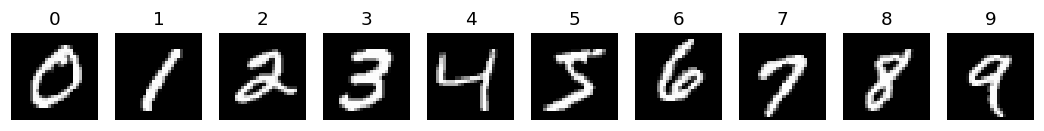

In [2]:
NPZ = os.path.join("..", "..", "data", "mnist", "mnist.npz")
if os.path.exists(NPZ):
    d = np.load(NPZ)
    xtr, ltr, xte, lte = d["train_images"], d["train_labels"], d["test_images"], d["test_labels"]
else:
    from torchvision.datasets import MNIST
    root = os.path.join("..", "..", "data", "mnist")
    tr, te = MNIST(root, train=True, download=True), MNIST(root, train=False, download=True)
    xtr, ltr, xte, lte = tr.data.numpy(), tr.targets.numpy(), te.data.numpy(), te.targets.numpy()

X_TR = torch.tensor(xtr.reshape(-1, 784) / 255.0, dtype=torch.float32, device=DEVICE)
X_TE = torch.tensor(xte.reshape(-1, 784) / 255.0, dtype=torch.float32, device=DEVICE)
L_TR = torch.tensor(ltr, dtype=torch.long, device=DEVICE)
L_TE = torch.tensor(lte, dtype=torch.long, device=DEVICE)
Y_TR = torch.nn.functional.one_hot(L_TR, 10).float()        # one-hot targets in {0, 1}^10
print(f"train {tuple(X_TR.shape)}, test {tuple(X_TE.shape)}, class counts (train): {torch.bincount(L_TR).tolist()}")

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for k, ax in enumerate(axes):
    ax.imshow(xtr[np.where(ltr == k)[0][0]], cmap="gray"); ax.set_title(str(k)); ax.axis("off")
plt.show()

## 2. Network and objective

- There are 3 runs, trained in parallel: every weight has shape `(runs, out, in)` and every bias `(runs, 1, out)`.
- The forward pass goes through the 60,000 training images in chunks, so the six perturbed networks of one SPSA step (2 perturbations × 3 runs) fit in GPU memory.

In [3]:
SIZES, BETA, RUNS = [784, 784, 196, 10], 1.0, 3
N_PARAMS = sum(i * o + o for i, o in zip(SIZES[:-1], SIZES[1:]))
print(f"network {'x'.join(map(str, SIZES))}: {N_PARAMS:,} parameters")
assert N_PARAMS == 771_270


def init_params(runs, seed):
    """Glorot-uniform weights and zero biases (the TensorFlow default for dense layers)."""
    g = torch.Generator().manual_seed(seed)
    ps = []
    for n_in, n_out in zip(SIZES[:-1], SIZES[1:]):
        lim = (6.0 / (n_in + n_out)) ** 0.5
        ps.append(((torch.rand(runs, n_out, n_in, generator=g) * 2 - 1) * lim).to(DEVICE))
        ps.append(torch.zeros(runs, 1, n_out, device=DEVICE))
    return ps


def forward(x, ps):
    """x: (n, 784) or (B, n, 784); ps: [W1, b1, W2, b2, W3, b3] with a leading batch dim B -> (B, n, 10)."""
    a = x
    for l in range(len(ps) // 2):
        a = torch.tanh(BETA * (a @ ps[2 * l].transpose(1, 2) + ps[2 * l + 1]))
    return a


CHUNK = 10_000


@torch.no_grad()
def error_per_image(ps, x=X_TR, y=Y_TR):
    """E = (1/n) sum_i ||y(x_i) - y_i||^2, one value per network (the scale of Fig. 2a)."""
    total = 0.0
    for s in range(0, x.shape[0], CHUNK):
        total = total + ((forward(x[s:s + CHUNK], ps) - y[s:s + CHUNK]) ** 2).sum(dim=(1, 2))
    return total / x.shape[0]


def objective(ps):
    """What SPSA minimises: the mean squared residual (tf.reduce_mean), i.e. E / 10."""
    return error_per_image(ps) / 10.0


@torch.no_grad()
def predict(ps, x):
    out = torch.cat([forward(x[s:s + CHUNK], ps) for s in range(0, x.shape[0], CHUNK)], dim=1)
    return out.argmax(dim=2)                                  # (B, n)


def accuracy(ps, x, labels):
    return (predict(ps, x) == labels).float().mean(dim=1)    # (B,)

network 784x784x196x10: 771,270 parameters


## 3. Layer-wise SPSA, exactly as in Sect. 4.2

Each epoch visits the layers bottom-up ($l = 1, 2, 3$). For every layer it makes **two separate calls of Algorithm 1**, first on the weights $W_l$ and then on the biases $b_l$ (the paper: *"Without this modification we did not observe any learning behavior"*). Each call runs:

$$\text{for } t = 1, \dots, 50: \quad a_t = \frac{0.1}{t}, \; c_t = \frac{0.1}{t^{1/6}}, \; \delta \sim \mathcal{U}\{-1, +1\}, \; \theta \leftarrow \theta - a_t\,\frac{E(\theta + c_t\delta) - E(\theta - c_t\delta)}{2c_t}\,\delta$$

**Cost per epoch:** 3 layers × 2 calls × 50 steps = **300 updates**, which is **600 full passes** over the 60,000 training images. The training error is logged **after every update** (for monitoring only, not counted as cost). Test accuracy is logged after every epoch.

`holistic=True` instead perturbs all 771,270 parameters in every step, with the same number of steps per epoch. This is the paper's holistic variant.

In [4]:
@torch.no_grad()
def train_spsa(epochs, a=0.1, c=0.1, t_max=50, holistic=False, seed=SEED, verbose=True):
    ps = init_params(RUNS, seed)
    gen = torch.Generator(device=DEVICE).manual_seed(seed + 1)
    hist = dict(step_E=[error_per_image(ps).cpu()], step_passes=[0], epoch_E=[error_per_image(ps).cpu()],
                epoch_test=[accuracy(ps, X_TE, L_TE).cpu()], epoch_train=[accuracy(ps, X_TR, L_TR).cpu()],
                epoch_time=[0.0])
    n_layers = len(SIZES) - 1
    # Each call of Algorithm 1 optimises one group of tensors: bottom-up W1, b1, W2, b2, W3, b3.
    calls = [[i] for l in range(n_layers) for i in (2 * l, 2 * l + 1)]
    if holistic:
        calls = [list(range(len(ps)))] * len(calls)         # same number of calls/steps, all parameters
    passes, t_start = 0, time.perf_counter()
    for epoch in range(1, epochs + 1):
        for group in calls:
            for t in range(1, t_max + 1):
                a_t, c_t = a / t, c / t ** (1.0 / 6.0)
                deltas = {i: torch.randint(0, 2, ps[i].shape, generator=gen, device=DEVICE).float() * 2 - 1 for i in group}
                plus = [p + c_t * deltas[i] if i in deltas else p for i, p in enumerate(ps)]
                minus = [p - c_t * deltas[i] if i in deltas else p for i, p in enumerate(ps)]
                both = [torch.cat([p, m]) for p, m in zip(plus, minus)]       # 2 * RUNS networks in one pass
                f = objective(both)
                diff = (f[:RUNS] - f[RUNS:]) / (2 * c_t)                     # (RUNS,)
                for i in group:
                    ps[i] = ps[i] - a_t * diff.view(-1, *[1] * (ps[i].dim() - 1)) * deltas[i]
                passes += 2
                hist["step_E"].append(error_per_image(ps).cpu())
                hist["step_passes"].append(passes)
        sync()
        hist["epoch_E"].append(error_per_image(ps).cpu())
        hist["epoch_test"].append(accuracy(ps, X_TE, L_TE).cpu())
        hist["epoch_train"].append(accuracy(ps, X_TR, L_TR).cpu())
        hist["epoch_time"].append(time.perf_counter() - t_start)
        if verbose:
            print(f"epoch {epoch:2d} | E per run {np.round(hist['epoch_E'][-1].numpy(), 3)} | test acc "
                  f"{np.round(100 * hist['epoch_test'][-1].numpy(), 1)} % | {hist['epoch_time'][-1]:.0f} s", flush=True)
    for k in ("step_E", "epoch_E", "epoch_test", "epoch_train"):
        hist[k] = torch.stack(hist[k]).numpy()
    hist["step_passes"] = np.array(hist["step_passes"])
    hist["updates_per_epoch"] = len(calls) * t_max
    return ps, hist

### 3.1 Holistic SPSA check (paper: *"the holistic variant of SPSA failed to learn the MNIST task"*)

This runs 2 epochs with the same gains and the same number of updates as layer-wise SPSA, but every step perturbs all 771,270 parameters.

In [5]:
sync(); t0 = time.perf_counter()
ps_hol, hist_hol = train_spsa(epochs=2, holistic=True)
sync(); print(f"holistic SPSA: {time.perf_counter() - t0:.0f} s")

epoch  1 | E per run [4.135 4.401 5.264] | test acc [28.1 25.6 28.9] % | 79 s


epoch  2 | E per run [4.931 4.613 5.315] | test acc [26.8 28.2 32.8] % | 159 s


holistic SPSA: 160 s


### 3.2 Layer-wise SPSA: 3 runs × 12 epochs

In [6]:
SPSA_EPOCHS = 12
sync(); t0 = time.perf_counter()
ps_spsa, hist_spsa = train_spsa(epochs=SPSA_EPOCHS)
sync(); TIME_SPSA = time.perf_counter() - t0
print(f"layer-wise SPSA: {TIME_SPSA:.0f} s for {RUNS} runs in parallel")

epoch  1 | E per run [2.193 2.197 2.037] | test acc [18.9 23.1 14.6] % | 79 s


epoch  2 | E per run [2.197 2.302 2.304] | test acc [25.9 25.4 22.4] % | 159 s


epoch  3 | E per run [2.234 2.405 2.365] | test acc [27.2 31.1 24.4] % | 238 s


epoch  4 | E per run [2.048 2.264 2.333] | test acc [36.3 38.  30. ] % | 317 s


epoch  5 | E per run [1.992 2.306 2.478] | test acc [39.6 41.6 32.4] % | 396 s


epoch  6 | E per run [2.223 2.312 2.418] | test acc [42.5 44.3 37.4] % | 475 s


... (3 outputs left out)

epoch 10 | E per run [2.334 2.604 2.509] | test acc [49.6 44.7 45.6] % | 792 s


epoch 11 | E per run [2.319 2.61  2.902] | test acc [49.4 47.4 43.7] % | 871 s


epoch 12 | E per run [2.555 2.619 2.85 ] | test acc [48.2 51.2 43.7] % | 951 s


layer-wise SPSA: 951 s for 3 runs in parallel


## 4. Baseline: `torch.optim.SGD`, learning rate 0.01

- **Settings:** the paper's learning rate of 0.01, mini-batches of 64, the same objective (mean squared residual), and the same initial networks as the SPSA runs (the same seed).
- **Shuffling:** every run reshuffles the data each epoch.
- **Logging:** $E$ and test accuracy are logged after every epoch, and the full training error is also logged every 50 steps for the loss-vs-evaluations plot.
- **Cost:** one step (forward + backward on 64 images) counts as $3 \times 64 / 60000$ full passes.

In [7]:
def train_sgd(epochs, lr=0.01, batch=64, seed=SEED, log_every=50):
    ps = [p.clone().requires_grad_(True) for p in init_params(RUNS, seed)]
    opt = torch.optim.SGD(ps, lr=lr)
    gen = torch.Generator(device=DEVICE).manual_seed(seed + 2)
    n = X_TR.shape[0]
    hist = dict(step_E=[error_per_image(ps).cpu()], step_passes=[0.0], epoch_E=[error_per_image(ps).cpu()],
                epoch_test=[accuracy(ps, X_TE, L_TE).cpu()], epoch_train=[accuracy(ps, X_TR, L_TR).cpu()],
                epoch_time=[0.0])
    passes, step, t_start = 0.0, 0, time.perf_counter()
    for epoch in range(1, epochs + 1):
        perm = torch.argsort(torch.rand(RUNS, n, generator=gen, device=DEVICE), dim=1)
        for s in range(0, n, batch):
            idx = perm[:, s:s + batch]                                  # each run its own mini-batch
            opt.zero_grad()
            loss = ((forward(X_TR[idx], ps) - Y_TR[idx]) ** 2).mean(dim=(1, 2)).sum()   # mean per run
            loss.backward()
            opt.step()
            passes += 3.0 * idx.shape[1] / n
            step += 1
            if step % log_every == 0:
                hist["step_E"].append(error_per_image(ps).cpu()); hist["step_passes"].append(passes)
        sync()
        hist["epoch_E"].append(error_per_image(ps).cpu())
        hist["epoch_test"].append(accuracy(ps, X_TE, L_TE).cpu())
        hist["epoch_train"].append(accuracy(ps, X_TR, L_TR).cpu())
        hist["epoch_time"].append(time.perf_counter() - t_start)
        if epoch % 5 == 0 or epoch == 1:
            print(f"epoch {epoch:2d} | E per run {np.round(hist['epoch_E'][-1].numpy(), 3)} | test acc "
                  f"{np.round(100 * hist['epoch_test'][-1].numpy(), 1)} % | {hist['epoch_time'][-1]:.0f} s", flush=True)
    for k in ("step_E", "epoch_E", "epoch_test", "epoch_train"):
        hist[k] = torch.stack(hist[k]).numpy()
    hist["step_passes"] = np.array(hist["step_passes"])
    return [p.detach() for p in ps], hist


SGD_EPOCHS = 30
sync(); t0 = time.perf_counter()
ps_sgd, hist_sgd = train_sgd(epochs=SGD_EPOCHS)
sync(); TIME_SGD = time.perf_counter() - t0
print(f"SGD: {TIME_SGD:.0f} s for {RUNS} runs in parallel")

epoch  1 | E per run [0.557 0.553 0.558] | test acc [80.6 80.3 80.4] % | 6 s


epoch  5 | E per run [0.405 0.406 0.41 ] | test acc [87.4 87.4 87.5] % | 29 s


epoch 10 | E per run [0.336 0.337 0.342] | test acc [90.  89.8 90. ] % | 59 s


epoch 15 | E per run [0.294 0.294 0.3  ] | test acc [91.4 91.1 91.4] % | 89 s


epoch 20 | E per run [0.266 0.266 0.271] | test acc [92.3 92.1 92.1] % | 117 s


epoch 25 | E per run [0.246 0.247 0.251] | test acc [93.  92.6 92.8] % | 146 s


epoch 30 | E per run [0.232 0.231 0.237] | test acc [93.3 93.2 93.1] % | 176 s


SGD: 181 s for 3 runs in parallel


## 5. Results

### 5.1 Per-run results and the paper-style average

A run is called **successful** if it learns: its final training error $E$ is below its starting value. The paper averages its curves over three successful runs, without defining success.

In [8]:
learned = lambda h: h["epoch_E"][-1] < h["epoch_E"][0]       # final training error below the starting value
ok_spsa, ok_sgd = learned(hist_spsa), learned(hist_sgd)


def metrics(ps):
    pred = predict(ps, X_TE).cpu().numpy()
    true = L_TE.cpu().numpy()
    out = []
    for p in pred:
        pr, rc, f1, _ = precision_recall_fscore_support(true, p, average="macro", zero_division=0)
        out.append((100 * (p == true).mean(), 100 * pr, 100 * rc, 100 * f1))
    return np.array(out), pred


M_SPSA, PRED_SPSA = metrics(ps_spsa)
M_SGD, PRED_SGD = metrics(ps_sgd)
M_HOL, _ = metrics(ps_hol)

rows = []
for name, h, M, ok, ep in (("Holistic SPSA", hist_hol, M_HOL, learned(hist_hol), 2),
                           ("Layer-wise SPSA", hist_spsa, M_SPSA, ok_spsa, SPSA_EPOCHS),
                           ("SGD (torch.optim.SGD)", hist_sgd, M_SGD, ok_sgd, SGD_EPOCHS)):
    passes = ep * 600 if "SPSA" in name else ep * 3
    for r in range(RUNS):
        rows.append((name, r, ep, f"{passes:,}", f"{h['epoch_E'][0][r]:.3f}", f"{h['epoch_E'][-1][r]:.3f}",
                     f"{100 * h['epoch_train'][-1][r]:.1f}", *(f"{v:.1f}" for v in M[r]), "yes" if ok[r] else "no"))
print_table("Per-run results (test metrics on the 10,000 test images; precision/recall/F1 are macro averages, %)",
            ["method", "run", "epochs", "full passes", "E start", "E end", "train acc", "test acc",
             "precision", "recall", "F1", "successful"], rows)

for name, h, ok in (("Layer-wise SPSA", hist_spsa, ok_spsa), ("SGD", hist_sgd, ok_sgd)):
    print(f"{name}: {ok.sum()} of {RUNS} runs successful")
ck = [0, 1, 2, 4, 6, 8, 10, 12]
avg = lambda h, ok, k: h[k][:, ok].mean(axis=1) if ok.any() else h[k].mean(axis=1)
print()
print_table("Paper-style average over successful runs, per epoch (E per image, test accuracy %)",
            ["epoch", "SPSA E", "SPSA test acc", "SGD E", "SGD test acc"],
            [(e, f"{avg(hist_spsa, ok_spsa, 'epoch_E')[e]:.3f}", f"{100 * avg(hist_spsa, ok_spsa, 'epoch_test')[e]:.1f}",
              f"{avg(hist_sgd, ok_sgd, 'epoch_E')[e]:.3f}", f"{100 * avg(hist_sgd, ok_sgd, 'epoch_test')[e]:.1f}") for e in ck])
print_table("SGD after more epochs (average over successful runs)", ["epoch", "SGD E", "SGD test acc"],
            [(e, f"{avg(hist_sgd, ok_sgd, 'epoch_E')[e]:.3f}", f"{100 * avg(hist_sgd, ok_sgd, 'epoch_test')[e]:.1f}")
             for e in (15, 20, 25, 30)])
print(f"Wall-clock: SPSA {TIME_SPSA:.0f} s ({SPSA_EPOCHS} epochs), SGD {TIME_SGD:.0f} s ({SGD_EPOCHS} epochs), "
      f"3 runs in parallel each")

Per-run results (test metrics on the 10,000 test images; precision/recall/F1 are macro averages, %)
method                | run | epochs | full passes | E start | E end | train acc | test acc | precision | recall | F1   | successful
----------------------+-----+--------+-------------+---------+-------+-----------+----------+-----------+--------+------+-----------
Holistic SPSA         | 0   | 2      | 1,200       | 2.436   | 4.931 | 26.7      | 26.8     | 24.9      | 26.2   | 24.9 | no        
Holistic SPSA         | 1   | 2      | 1,200       | 2.132   | 4.613 | 27.3      | 28.2     | 28.0      | 28.1   | 27.2 | no        
Holistic SPSA         | 2   | 2      | 1,200       | 2.395   | 5.315 | 31.6      | 32.8     | 31.2      | 31.8   | 29.4 | no        
Layer-wise SPSA       | 0   | 12     | 7,200       | 2.436   | 2.555 | 47.1      | 48.2     | 46.9      | 47.2   | 45.1 | no        
Layer-wise SPSA       | 1   | 12     | 7,200       | 2.132   | 2.619 | 49.9      | 51.1     | 49.8    

### 5.2 Fig. 2 style: training error and test accuracy vs. epoch

Thick lines are the averages over the successful runs, as in the paper; thin lines are the individual runs.

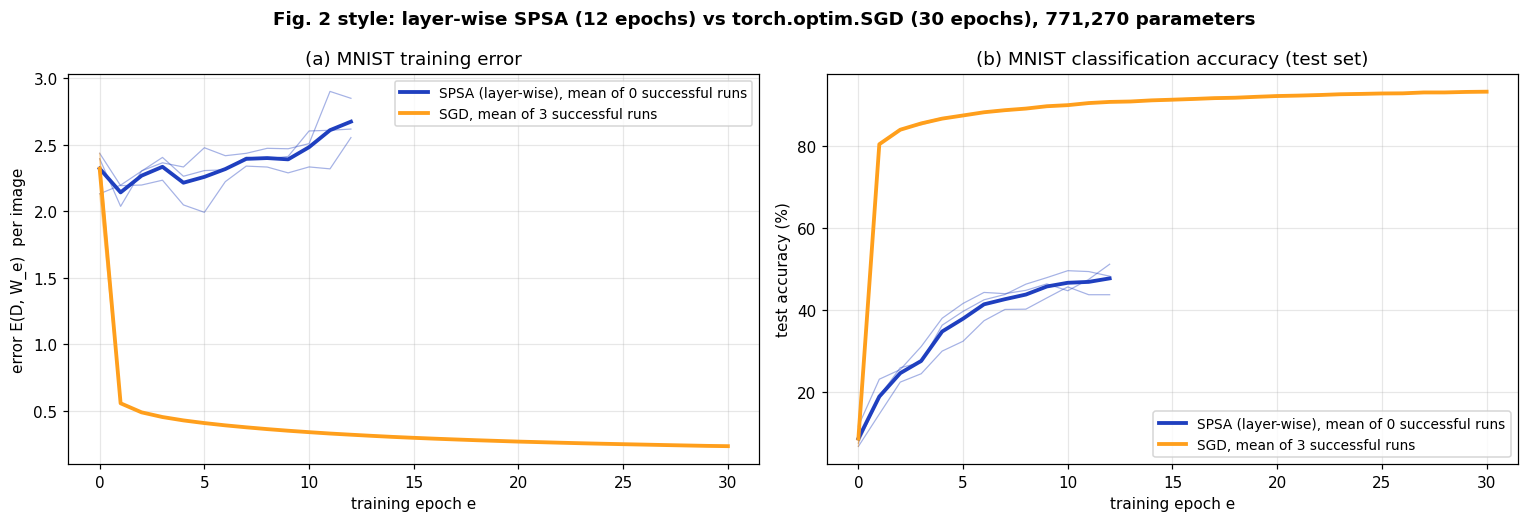

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for h, ok, color, name in ((hist_spsa, ok_spsa, "#1f3fbf", "SPSA (layer-wise)"), (hist_sgd, ok_sgd, "#ff9f1c", "SGD")):
    ep = np.arange(len(h["epoch_E"]))
    for r in range(RUNS):
        axes[0].plot(ep, h["epoch_E"][:, r], color=color, lw=0.8, alpha=0.4)
        axes[1].plot(ep, 100 * h["epoch_test"][:, r], color=color, lw=0.8, alpha=0.4)
    axes[0].plot(ep, avg(h, ok, "epoch_E"), color=color, lw=2.5, label=f"{name}, mean of {ok.sum()} successful runs")
    axes[1].plot(ep, 100 * avg(h, ok, "epoch_test"), color=color, lw=2.5, label=f"{name}, mean of {ok.sum()} successful runs")
axes[0].set(xlabel="training epoch e", ylabel="error E(D, W_e)  per image", title="(a) MNIST training error")
axes[1].set(xlabel="training epoch e", ylabel="test accuracy (%)", title="(b) MNIST classification accuracy (test set)")
for ax in axes:
    ax.legend(fontsize=9)
fig.suptitle("Fig. 2 style: layer-wise SPSA (12 epochs) vs torch.optim.SGD (30 epochs), 771,270 parameters", fontweight="bold")
plt.tight_layout()
plt.show()

### 5.3 Loss vs. computational cost

**Per update (left):** SPSA's error is logged after every one of its 3,600 updates. The steps in the curve appear where the active layer or tensor changes, every 50 updates.

**Per full pass over the training set (right):** compute measured the same way for both methods (SPSA: 2 passes per update; SGD: forward + backward ≈ 3 × the mini-batch fraction).

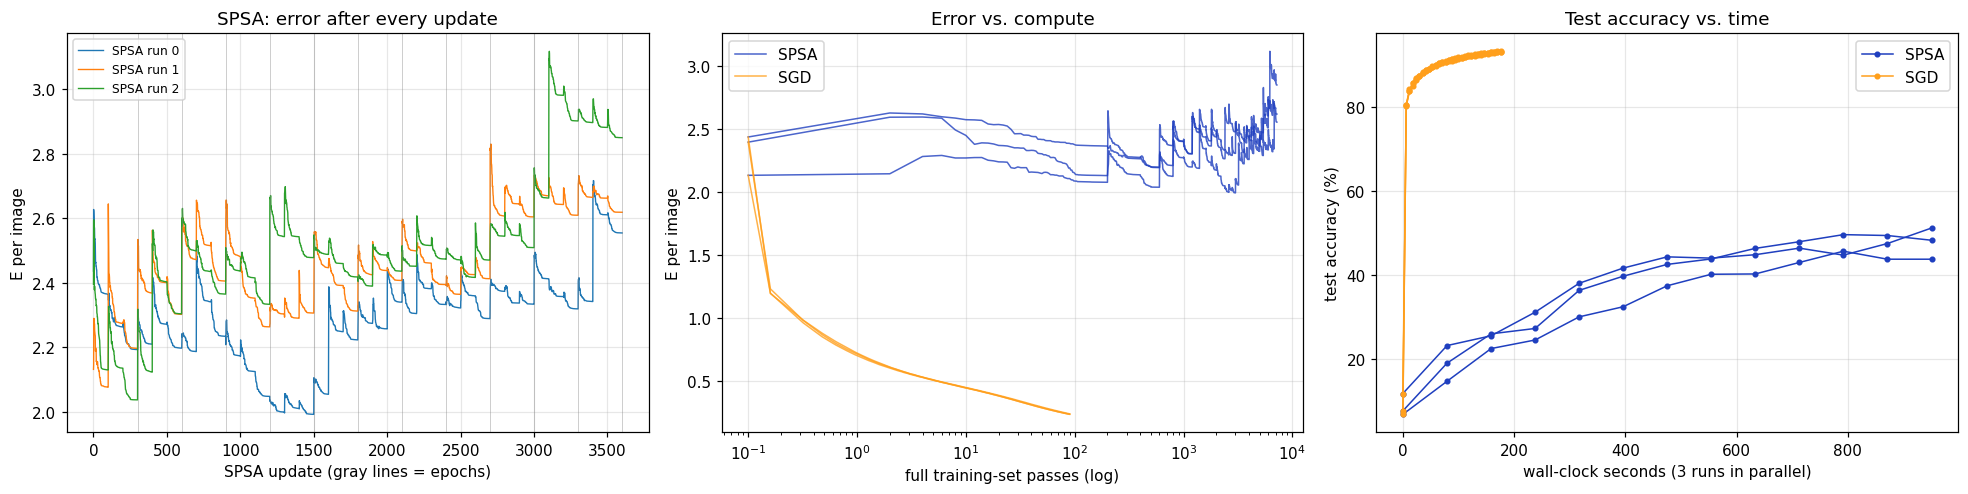

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
upd = np.arange(len(hist_spsa["step_E"]))
for r in range(RUNS):
    axes[0].plot(upd, hist_spsa["step_E"][:, r], lw=0.9, label=f"SPSA run {r}")
for k in range(1, SPSA_EPOCHS + 1):
    axes[0].axvline(k * hist_spsa["updates_per_epoch"], color="gray", lw=0.5, alpha=0.5)
axes[0].set(xlabel="SPSA update (gray lines = epochs)", ylabel="E per image", title="SPSA: error after every update")
axes[0].legend(fontsize=8)
for h, color, name in ((hist_spsa, "#1f3fbf", "SPSA"), (hist_sgd, "#ff9f1c", "SGD")):
    for r in range(RUNS):
        axes[1].plot(np.maximum(h["step_passes"], 1e-1), h["step_E"][:, r], color=color, lw=1, alpha=0.8,
                     label=name if r == 0 else None)
axes[1].set(xscale="log", xlabel="full training-set passes (log)", ylabel="E per image", title="Error vs. compute")
axes[1].legend()
for h, color, name in ((hist_spsa, "#1f3fbf", "SPSA"), (hist_sgd, "#ff9f1c", "SGD")):
    for r in range(RUNS):
        axes[2].plot(h["epoch_time"], 100 * h["epoch_test"][:, r], color=color, marker="o", ms=3, lw=1,
                     label=name if r == 0 else None)
axes[2].set(xlabel="wall-clock seconds (3 runs in parallel)", ylabel="test accuracy (%)", title="Test accuracy vs. time")
axes[2].legend()
plt.tight_layout()
plt.show()

### 5.4 Confusion matrices and per-class results (best run of each method)

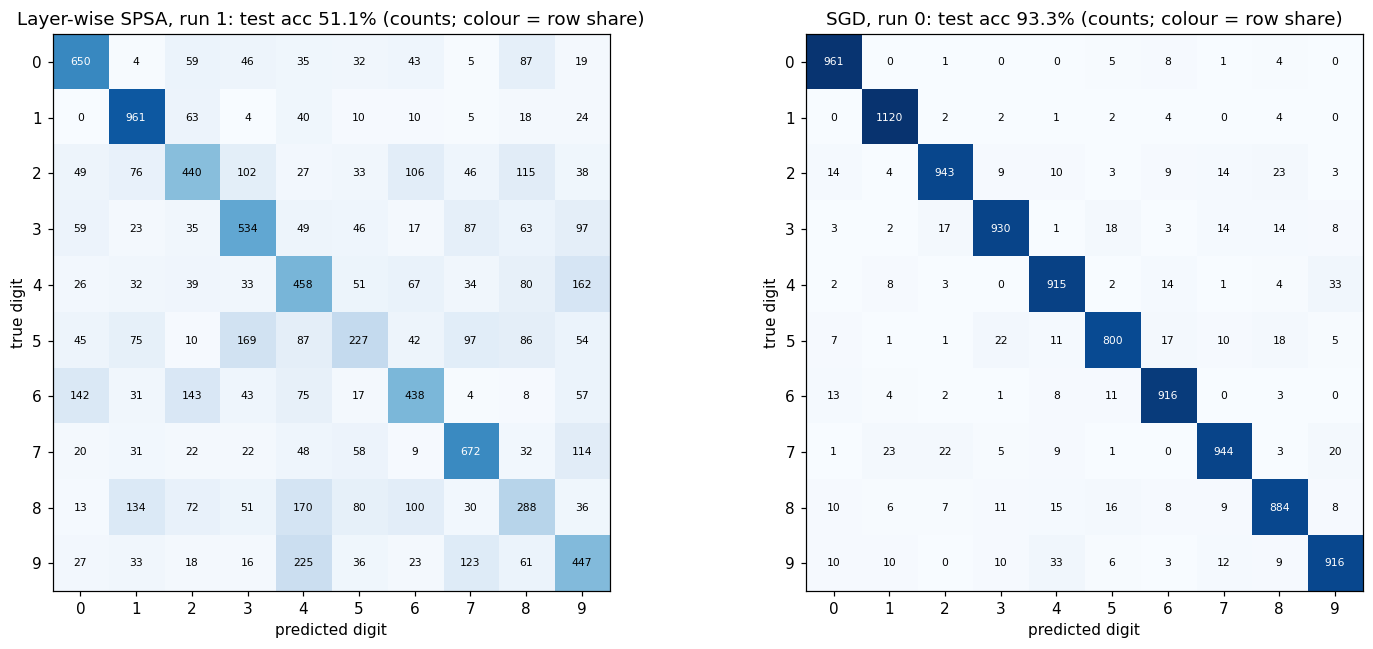

Per-class test metrics, best run of each method (%)
digit | count | SPSA precision | SPSA recall | SPSA F1 | SGD precision | SGD recall | SGD F1
------+-------+----------------+-------------+---------+---------------+------------+-------
0     | 980   | 63.0           | 66.3        | 64.6    | 94.1          | 98.1       | 96.1  
1     | 1135  | 68.6           | 84.7        | 75.8    | 95.1          | 98.7       | 96.8  
2     | 1032  | 48.8           | 42.6        | 45.5    | 94.5          | 91.4       | 92.9  
3     | 1010  | 52.4           | 52.9        | 52.6    | 93.9          | 92.1       | 93.0  
4     | 982   | 37.7           | 46.6        | 41.7    | 91.2          | 93.2       | 92.2  
5     | 892   | 38.5           | 25.4        | 30.6    | 92.6          | 89.7       | 91.1  
6     | 958   | 51.2           | 45.7        | 48.3    | 93.3          | 95.6       | 94.4  
7     | 1028  | 60.9           | 65.4        | 63.1    | 93.9          | 91.8       | 92.9  
8     | 974   | 34

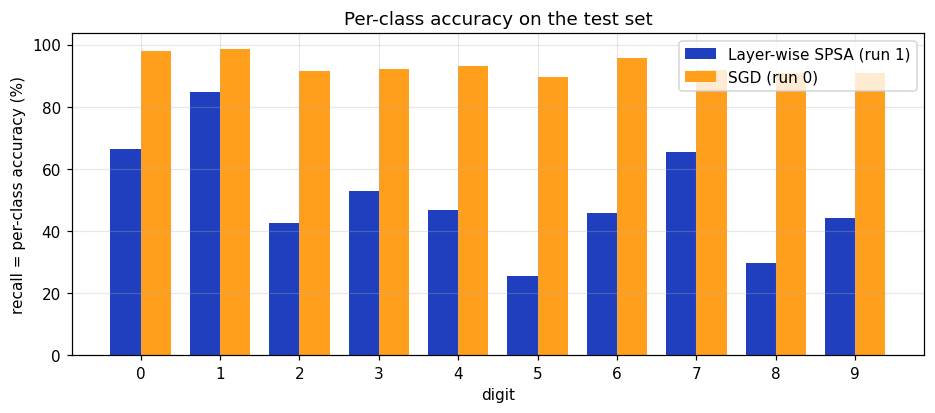

In [11]:
best_spsa, best_sgd = int(M_SPSA[:, 0].argmax()), int(M_SGD[:, 0].argmax())
true = L_TE.cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, name, r in ((axes[0], PRED_SPSA, "Layer-wise SPSA", best_spsa), (axes[1], PRED_SGD, "SGD", best_sgd)):
    cm = confusion_matrix(true, pred[r], labels=range(10))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > 0.6 else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.grid(False)
    ax.set(xlabel="predicted digit", ylabel="true digit",
           title=f"{name}, run {r}: test acc {100 * (pred[r] == true).mean():.1f}% (counts; colour = row share)")
plt.tight_layout()
plt.show()

pr_s, rc_s, f1_s, sup = precision_recall_fscore_support(true, PRED_SPSA[best_spsa], labels=range(10), zero_division=0)
pr_g, rc_g, f1_g, _ = precision_recall_fscore_support(true, PRED_SGD[best_sgd], labels=range(10), zero_division=0)
print_table("Per-class test metrics, best run of each method (%)",
            ["digit", "count", "SPSA precision", "SPSA recall", "SPSA F1", "SGD precision", "SGD recall", "SGD F1"],
            [(k, sup[k], f"{100 * pr_s[k]:.1f}", f"{100 * rc_s[k]:.1f}", f"{100 * f1_s[k]:.1f}",
              f"{100 * pr_g[k]:.1f}", f"{100 * rc_g[k]:.1f}", f"{100 * f1_g[k]:.1f}") for k in range(10)])

fig, ax = plt.subplots(figsize=(10, 3.8))
w = 0.38
ax.bar(np.arange(10) - w / 2, 100 * rc_s, w, label=f"Layer-wise SPSA (run {best_spsa})", color="#1f3fbf")
ax.bar(np.arange(10) + w / 2, 100 * rc_g, w, label=f"SGD (run {best_sgd})", color="#ff9f1c")
ax.set(xticks=range(10), xlabel="digit", ylabel="recall = per-class accuracy (%)", title="Per-class accuracy on the test set")
ax.legend()
plt.show()

### 5.5 Example predictions

The first row shows test digits that SPSA gets wrong and SGD gets right. The second shows random test digits with both methods' predictions (best run of each).

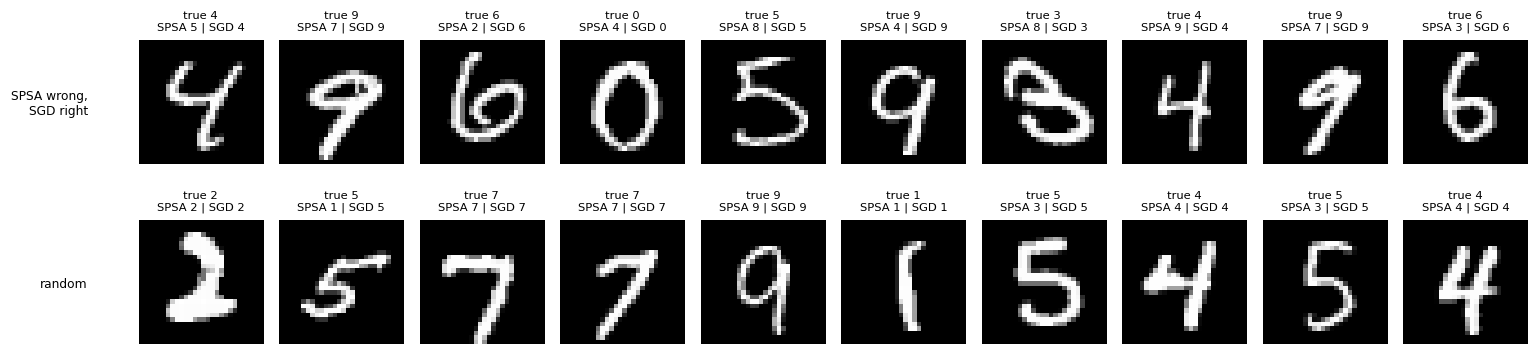

In [12]:
ps_wrong = np.where((PRED_SPSA[best_spsa] != true) & (PRED_SGD[best_sgd] == true))[0][:10]
rand = np.random.default_rng(0).choice(len(true), 10, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(14, 3.6))
for row, idx in enumerate((ps_wrong, rand)):
    for k, ax in enumerate(axes[row]):
        ax.axis("off")
        if k < len(idx):
            i = idx[k]
            ax.imshow(xte[i], cmap="gray")
            ax.set_title(f"true {true[i]}\nSPSA {PRED_SPSA[best_spsa][i]} | SGD {PRED_SGD[best_sgd][i]}", fontsize=7.5)
axes[0, 0].text(-12, 14, "SPSA wrong,\nSGD right", fontsize=8, ha="right", va="center")
axes[1, 0].text(-12, 14, "random", fontsize=8, ha="right", va="center")
plt.tight_layout()
plt.show()

In [13]:
# Numbers used in the takeaways below, printed from this run
print("holistic SPSA, test acc per run after 2 epochs:", np.round(M_HOL[:, 0], 1), "| E:", np.round(hist_hol["epoch_E"][-1], 3))
print("layer-wise SPSA, test acc per run:", np.round(M_SPSA[:, 0], 1), "| E:", np.round(hist_spsa["epoch_E"][-1], 3),
      "| successful:", ok_spsa)
print("layer-wise SPSA, mean test acc over successful runs per epoch:", np.round(100 * avg(hist_spsa, ok_spsa, "epoch_test"), 1))
print("SGD, test acc per run:", np.round(M_SGD[:, 0], 1), "| E:", np.round(hist_sgd["epoch_E"][-1], 3))
print("SGD, mean test acc per epoch:", np.round(100 * avg(hist_sgd, ok_sgd, "epoch_test"), 1))
print(f"full passes: SPSA {SPSA_EPOCHS * 600:,}, SGD {SGD_EPOCHS * 3}")

holistic SPSA, test acc per run after 2 epochs: [26.8 28.2 32.8] | E: [4.931 4.613 5.315]
layer-wise SPSA, test acc per run: [48.2 51.2 43.7] | E: [2.555 2.619 2.85 ] | successful: [False False False]
layer-wise SPSA, mean test acc over successful runs per epoch: [ 8.6 18.9 24.6 27.6 34.7 37.9 41.4 42.6 43.8 45.7 46.6 46.8 47.7]
SGD, test acc per run: [93.3 93.2 93.1] | E: [0.232 0.231 0.237]
SGD, mean test acc per epoch: [ 8.6 80.4 83.9 85.5 86.7 87.4 88.2 88.7 89.1 89.7 89.9 90.4 90.7 90.8
 91.1 91.3 91.4 91.6 91.8 92.  92.2 92.3 92.4 92.6 92.7 92.8 92.8 93.
 93.  93.2 93.2]
full passes: SPSA 7,200, SGD 90


## 6. Takeaways

All numbers come from the run above: 3 runs per method, 771,270 parameters, on the GPU.

### What matches the paper
- **Holistic SPSA fails.** After 2 epochs, its training error $E$ has roughly **doubled** in all 3 runs (2.13–2.44 → 4.61–5.32). Test accuracy sits at 27–33%, a level layer-wise SPSA passes by epoch 4. This agrees with the paper: *"the holistic variant of SPSA failed to learn the MNIST task."*
- **Layer-wise SPSA learns from forward passes only.** Test accuracy rises steadily in all 3 runs: from 8.6% at the start to **48.2%, 51.2% and 43.7%** after 12 epochs (mean 47.7%). This is with no gradients and no backward pass, on a network of close to a million parameters. That is the paper's stated goal: *"to show that SPSA training is feasible even for a total number of parameters close to a million."*

### What does not match the paper
- **The paper reaches more.** In its Fig. 2, layer-wise SPSA reaches **≈ 72% test accuracy** and an error of **≈ 1.3** within 12 epochs. Here it reaches **47.7%**.
- **Our training error goes up, not down.** It ends at 2.56–2.85, above its starting value of 2.13–2.44. So **no run meets our success rule** (final $E$ below the starting $E$). The "paper-style average" rows and the thick SPSA curve are therefore the **mean of all 3 runs**; the legend's "mean of 0 successful runs" refers to this.
- **The error-after-every-update plot shows why.** Each call of Algorithm 1 restarts at $t = 1$, where the step $a_1 = 0.1$ is largest. In SPSA, every coordinate of the active tensor moves by the same amount (up to 614,656 weights in $W_1$), so each call begins with an upward jump in $E$. The jump decays over the call's remaining 49 steps, but not completely.
  - The **argmax** of the outputs still improves, so accuracy rises while the squared error, which also counts the non-target outputs, does not.
- **Likely reasons for the gap.** The paper does not report its initialisation, input scaling, exact objective scale, gain exponents or whether it used mini-batches. With $a = 0.1$, each of these changes the effective step size.
  - The earlier version of this repository used Spall's exponents ($\alpha = 0.602$, $\gamma = 0.101$) instead of the paper's ($\alpha = 1$, $\gamma = 1/6$). Its result was similar: about 50% after 12 epochs, with the error rising.
  - We kept the paper's stated $a = 0.1$, $c = 0.1$, $t_{\max} = 50$ rather than tuning them to match its figure.

### SPSA vs. SGD
- **SGD is far ahead.** `torch.optim.SGD` with the paper's learning rate of 0.01 (batch 64) reaches **80.4%** after 1 epoch and **93.2%** after 30 epochs, with the same result in all 3 runs ($E$ = 0.23).
- **It also uses far less compute:**
  - 90 full passes over the training set, against **7,200** for 12 epochs of SPSA;
  - 181 s against 951 s of wall-clock time.
- **The paper's own gradient baseline was much slower** (≈ 40% at epoch 12, ≈ 75% after 250 epochs). Its *"SPSA already learns within the first twelve epochs"* compares against that slow GD. Mini-batch SGD with the same learning rate overtakes SPSA from the first epoch.
- **The paper itself rules out reading this as a quantitative contest:** *"we neither aim for a quantitative comparison between the two approaches nor for achieving state of the art results (<1% error rate)."*
- **Per class,** SPSA's best run (51.2%) does best on 1 and 0 (recall 84.7% and 66.3%) and worst on 5 and 8 (25.4% and 29.6%). SGD stays between 89.7% and 98.7% recall on every digit.

### In one line
Layer-wise SPSA trains a 771k-parameter network without backpropagation, and holistic SPSA does not, as the paper says. But at the paper's settings, SPSA reaches 48% here, not the paper's ≈ 72%. Standard SGD reaches 93% with about 1/80 of the compute.